# Eksperimen 2: Pelatihan Model Hibrid RT-DETR + ConvNeXt V2 + CBAM

**Judul Skripsi:**  
IMPLEMENTASI HIBRID RT-DETR DAN CONVNEXT V2 TERINTEGRASI CBAM UNTUK KLASIFIKASI DAN KUANTIFIKASI KUMPULAN BIJI FAMILI FABACEAE

**Mahasiswa:** Refael Juari Siagian (NIM: 231402055)  
**Hardware:** NVIDIA GeForce RTX 4070 (12 GB VRAM)  
**Dataset:** Biji Famili Fabaceae (*Albizia lophantha*, *Clitoria ternatea*)

---  
## 1. Verifikasi Lingkungan & Hardware GPU

In [1]:
import sys
from pathlib import Path

# Pastikan ultralytics_repo terhubung langsung ke sys.path
repo_path = str(Path('ultralytics_repo').resolve())
if repo_path not in sys.path:
    sys.path.insert(0, repo_path)

import torch
import ultralytics

print("=" * 65)
print(f"PyTorch Version   : {torch.__version__}")
print(f"CUDA Tersedia     : {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"Nama GPU          : {torch.cuda.get_device_name(0)}")
    vram_gb = torch.cuda.get_device_properties(0).total_memory / (1024 ** 3)
    print(f"Total VRAM GPU    : {vram_gb:.2f} GB")
print("=" * 65)
ultralytics.checks()

Ultralytics 8.4.215  Python-3.10.22 torch-2.5.1+cu121 CUDA:0 (NVIDIA GeForce RTX 4070, 12282MiB)
Setup complete  (24 CPUs, 31.9 GB RAM, 907.1/10718.4 GB disk)


---  
## 2. Verifikasi File Konfigurasi Dataset (`dataset/data.yaml`)
Cell ini memeriksa kelengkapan file citra di folder `train/`, `valid/`, dan `test/` serta membaca nama-nama kelas spesies biji Fabaceae.

In [2]:
import os
try:
    import yaml
except ImportError:
    import subprocess, sys
    print("Menginstal pyyaml otomatis...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "pyyaml"])
    import yaml

data_yaml_path = "dataset/data.yaml"
with open(data_yaml_path, "r") as f:
    data_cfg = yaml.safe_load(f)

classes = data_cfg.get("names", [])
print("=" * 65)
print(f"Path Dataset      : {data_cfg.get('path')}")
print(f"Jumlah Kelas (nc) : {len(classes)}")
print(f"Daftar Spesies    : {classes}")
print("-" * 65)

valid_exts = (".jpg", ".jpeg", ".png", ".bmp", ".heic", ".heif")
for split in ["train", "valid", "test"]:
    img_dir = os.path.join("dataset", split, "images")
    lbl_dir = os.path.join("dataset", split, "labels")
    if os.path.exists(img_dir):
        n_imgs = len([f for f in os.listdir(img_dir) if f.lower().endswith(valid_exts)])
        n_lbls = len([f for f in os.listdir(lbl_dir) if f.endswith('.txt') and not f.startswith('.')]) if os.path.exists(lbl_dir) else 0
        print(f"Split {split:<6} : {n_imgs:>4} citra  |  {n_lbls:>4} file label (.txt)")
    else:
        print(f"Split {split:<6} : Folder {img_dir} belum ditemukan.")
print("=" * 65)

Path Dataset      : dataset
Jumlah Kelas (nc) : 2
Daftar Spesies    : ['Albizia lophantha', 'Clitoria ternatea']
-----------------------------------------------------------------
Split train  :   56 citra  |    56 file label (.txt)
Split valid  :   12 citra  |    12 file label (.txt)
Split test   :   12 citra  |    12 file label (.txt)


---  
## 3. Inisialisasi Model Hibrid (RT-DETR + ConvNeXt V2 + CBAM)
Memuat arsitektur model dari file konfigurasi `configs/rtdetr_convnextv2_cbam.yaml`.

In [3]:
from ultralytics import RTDETR

model_yaml = "configs/rtdetr_convnextv2_cbam.yaml"
print(f"Menginisialisasi arsitektur dari: {model_yaml}")
model = RTDETR(model_yaml)
print("Model hibrid berhasil disusun!")

Menginisialisasi arsitektur dari: configs/rtdetr_convnextv2_cbam.yaml
WARNING no model scale passed. Assuming scale='l'.
Model hibrid berhasil disusun!


---  
## 4. Pelatihan Model (*Training Pipeline*) di GPU NVIDIA RTX 4070

Pengaturan hiperparameter (sesuai Bab 3 / Dokumen Metodologi Skripsi):
- **`imgsz=640`**: Resolusi standar dengan letterboxing otomatis untuk menjaga rasio morfologi asli biji.
- **`epochs=50`**: Jumlah putaran iterasi pelatihan (bisa ditambah ke 100 untuk eksperimen final).
- **`batch=8`**: Ukuran batch optimal untuk VRAM 12 GB GPU RTX 4070.
- **`optimizer='AdamW'`**: Pengoptimal dengan pembobotan *weight decay* yang stabil untuk model transformer.
- **`device=0`**: Menjalankan pelatihan pada GPU NVIDIA GeForce RTX 4070.

In [ ]:
# Jalankan proses pelatihan
results = model.train(
    data="dataset/data.yaml",
    epochs=100,             # Jumlah epoch pelatihan
    imgsz=640,             # Ukuran citra masukan
    batch=8,               # Ukuran batch per iterasi
    workers=4,             # Jumlah worker CPU untuk memuat data
    device=0,              # GPU RTX 4070
    optimizer="AdamW",      # Optimizer AdamW sesuai metodologi
    lr0=0.0001,
    lrf=0.1,
    warmup_epochs=5,
    amp=False,
    project="runs/train",   # Direktori utama penyimpanan hasil
    name="rtdetr_convnextv2_cbam_fabaceae-2", # Nama folder eksperimen
    save=True,             # Simpan bobot terbaik (best.pt)
    plots=True             # Buat grafik otomatis (loss, mAP, confusion matrix)
)

print("Pelatihan selesai! Bobot terbaik tersimpan di runs/train/rtdetr_convnextv2_cbam_fabaceae/weights/best.pt")

Ultralytics 8.4.215  Python-3.10.22 torch-2.5.1+cu121 CUDA:0 (NVIDIA GeForce RTX 4070, 12282MiB)
engine\trainer: agnostic_nms=False, amp=False, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.0001, lrf=0.1, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=configs/rtdetr_convnextv2_cbam.yaml, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=rtdetr_convnextv2_cbam_fabacea

d:\miniconda\envs\skripsi_env\lib\site-packages\torch\autograd\graph.py:825: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\builder\windows\pytorch\aten\src\ATen\Context.cpp:95.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
d:\miniconda\envs\skripsi_env\lib\site-packages\torch\autograd\graph.py:825: UserWarning: adaptive_max_pool2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internall

      1/100      8.59G      1.991     0.4845     0.6704        286        640: 100% ━━━━━━━━━━━━ 7/7 1.0s/it 7.3s0.5s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 1.3s/it 1.3s
                   all         12        300          0          0          0          0

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size
      2/100       8.7G      2.037     0.4023     0.8692        303        640: 0% ──────────── 0/7  1.2s

d:\miniconda\envs\skripsi_env\lib\site-packages\torch\autograd\graph.py:825: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\builder\windows\pytorch\aten\src\ATen\Context.cpp:95.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
d:\miniconda\envs\skripsi_env\lib\site-packages\torch\autograd\graph.py:825: UserWarning: adaptive_max_pool2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internall

      2/100       8.7G      2.116     0.3774     0.9602        312        640: 100% ━━━━━━━━━━━━ 7/7 1.0s/it 7.3s1.1ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 1.4s/it 1.4s
                   all         12        300   0.000139    0.00333   9.29e-07   9.29e-08

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size
      3/100      8.72G      2.366     0.2878      1.177        272        640: 0% ──────────── 0/7  1.1s

d:\miniconda\envs\skripsi_env\lib\site-packages\torch\autograd\graph.py:825: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\builder\windows\pytorch\aten\src\ATen\Context.cpp:95.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
d:\miniconda\envs\skripsi_env\lib\site-packages\torch\autograd\graph.py:825: UserWarning: adaptive_max_pool2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internall

... (191 outputs left out)

d:\miniconda\envs\skripsi_env\lib\site-packages\torch\autograd\graph.py:825: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\builder\windows\pytorch\aten\src\ATen\Context.cpp:95.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
d:\miniconda\envs\skripsi_env\lib\site-packages\torch\autograd\graph.py:825: UserWarning: adaptive_max_pool2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internall

     99/100       8.8G     0.6227     0.8721     0.1425        201        640: 100% ━━━━━━━━━━━━ 7/7 2.7it/s 2.6s0.4s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 1.0s/it 1.0s
                   all         12        300      0.106      0.903      0.224      0.087

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size
    100/100      8.81G     0.5354     0.9335     0.1232        202        640: 0% ──────────── 0/7  0.7s

d:\miniconda\envs\skripsi_env\lib\site-packages\torch\autograd\graph.py:825: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\builder\windows\pytorch\aten\src\ATen\Context.cpp:95.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
d:\miniconda\envs\skripsi_env\lib\site-packages\torch\autograd\graph.py:825: UserWarning: adaptive_max_pool2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internall

    100/100      8.81G     0.6161     0.8831     0.1406        200        640: 100% ━━━━━━━━━━━━ 7/7 2.4it/s 2.9s0.4s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 1.0s/it 1.0s
                   all         12        300      0.106      0.903      0.226     0.0883

100 epochs completed in 0.278 hours.
Optimizer stripped from \\data_science\homes\pc2 (save your files in here)\231402055\bijii\runs\detect\runs\train\rtdetr_convnextv2_cbam_fabaceae-2\weights\last.pt, 50.4MB
Optimizer stripped from \\data_science\homes\pc2 (save your files in here)\231402055\bijii\runs\detect\runs\train\rtdetr_convnextv2_cbam_fabaceae-2\weights\best.pt, 50.4MB

Validating \\data_science\homes\pc2 (save your files in here)\231402055\bijii\runs\detect\runs\train\rtdetr_convnextv2_cbam_fabaceae-2\weights\best.pt...
Ultralytics 8.4.215  Python-3.10.22 torch-2.5.1+cu121 CUDA:0 (NVIDIA GeForce RTX 4070, 12282MiB)
rtdetr_convnextv2_cbam summary (fu

---  
## 5. Evaluasi Kinerja pada Data Uji (*Testing Set*)
Cell ini menguji model terbaik (**`best.pt`**) pada data uji murni (*test split*) untuk mengukur metrik standar Computer Vision:
- **mAP@50** dan **mAP@50-95** (Akurasi Lokalisasi & Deteksi Kotak)
- **Precision** dan **Recall**
- **F1-Score**

In [9]:
best_weights = "runs/detect/runs/train/rtdetr_convnextv2_cbam_fabaceae-2/weights/best.pt"

# Muat model dengan bobot terbaik hasil training
trained_model = RTDETR(best_weights)

# Evaluasi pada split data uji (test set)
metrics = trained_model.val(data="dataset/data.yaml", split="test")

print("=" * 65)
print("HASIL EVALUASI METRIK PADA DATA UJI (TEST SET):")
print(f"mAP@50       : {metrics.box.map50:.4f}")
print(f"mAP@50-95    : {metrics.box.map:.4f}")
print(f"Precision    : {metrics.box.mp:.4f}")
print(f"Recall       : {metrics.box.mr:.4f}")
f1 = 2 * (metrics.box.mp * metrics.box.mr) / (metrics.box.mp + metrics.box.mr + 1e-16)
print(f"F1-Score     : {f1:.4f}")
print("=" * 65)

Ultralytics 8.4.215  Python-3.10.22 torch-2.5.1+cu121 CUDA:0 (NVIDIA GeForce RTX 4070, 12282MiB)
rtdetr_convnextv2_cbam summary (fused): 270 layers, 24,201,936 parameters, 0 gradients, 74.1 GFLOPs
val: Fast image access  (ping: 0.1±0.0 ms, read: 70.2±19.7 MB/s, size: 2478.6 KB)
val: Scanning \\data_science\homes\pc2 (save your files in here)\231402055\bijii\dataset\test\labels.cache... 12 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 12/12  0.0s
val: \\data_science\homes\pc2 (save your files in here)\231402055\bijii\dataset\test\images\Salinan 20260506_141935_jpg.rf.ugu1rLKDkN0ggz3J13aq.jpg: corrupt JPEG restored and saved
val: \\data_science\homes\pc2 (save your files in here)\231402055\bijii\dataset\test\images\Salinan 20260506_142358_jpg.rf.XPa4y2lphn1qwkfG7KeI.jpg: corrupt JPEG restored and saved
val: \\data_science\homes\pc2 (save your files in here)\231402055\bijii\dataset\test\images\Salinan 20260603_134512_jpg.rf.zKEMVvUkQ3s4M32rvF4Q.jpg: corrupt JPEG restored and saved
v

---  
## 6. Kuantifikasi Biji & Visualisasi Prediksi Deteksi
Sesuai tujuan skripsi untuk melakukan **klasifikasi sekaligus kuantifikasi (penghitungan jumlah total butir biji)** pada kumpulan biji Fabaceae.


image 1/1 \\data_science\homes\pc2 (save your files in here)\231402055\bijii\dataset\test\images\Salinan 20260506_141935_jpg.rf.ugu1rLKDkN0ggz3J13aq.jpg: 640x640 97 Albizia lophanthas, 184 Clitoria ternateas, 300.0ms
Speed: 3.3ms preprocess, 300.0ms inference, 0.6ms postprocess per image at shape (1, 3, 640, 640)
Citra Uji                  : Salinan 20260506_141935_jpg.rf.ugu1rLKDkN0ggz3J13aq.jpg
Total Butir Biji Terdeteksi: 281 butir


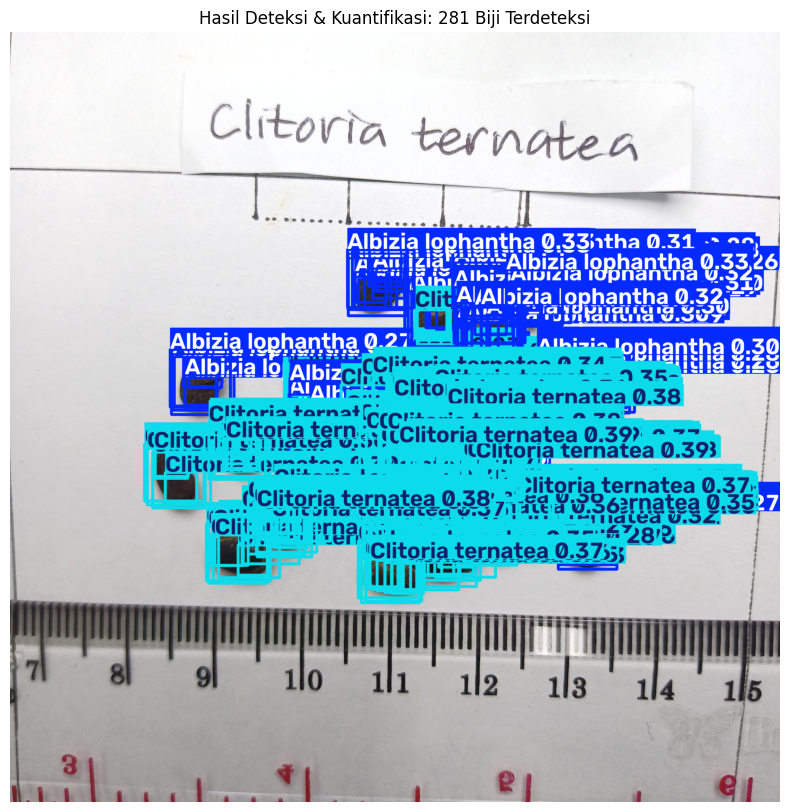

In [11]:
import glob
import cv2
import matplotlib.pyplot as plt

# Ambil citra dari data uji
test_images = glob.glob("dataset/test/images/*.jpg") + glob.glob("dataset/test/images/*.png")

if test_images:
    sample_img_path = test_images[0]
    pred_results = trained_model.predict(sample_img_path, conf=0.25, device=0)
    
    # Hitung jumlah biji terdeteksi per kelas
    detected_boxes = pred_results[0].boxes
    total_count = len(detected_boxes)
    
    print("=" * 65)
    print(f"Citra Uji                  : {os.path.basename(sample_img_path)}")
    print(f"Total Butir Biji Terdeteksi: {total_count} butir")
    print("=" * 65)
    
    # Tampilkan gambar hasil prediksi dengan bounding box & label spesies
    res_plot = pred_results[0].plot()
    plt.figure(figsize=(10, 10))
    plt.imshow(cv2.cvtColor(res_plot, cv2.COLOR_BGR2RGB))
    plt.title(f"Hasil Deteksi & Kuantifikasi: {total_count} Biji Terdeteksi")
    plt.axis("off")
    plt.show()
else:
    print("Belum ada citra di folder dataset/test/images/ untuk divisualisasikan.")